## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [301]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ashley Tibebe

**Date:** 10/19/2026

In [302]:
# Your Phase 1 solution to the problem goes here.
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

In [303]:
#Q1:
import matplotlib.pyplot as plt
import numpy as np

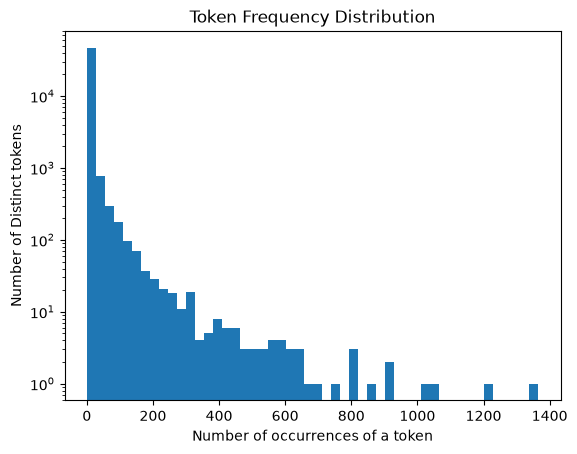

In [304]:
plt.hist([freq for token, freq in token_freq], bins=50)
plt.title('Token Frequency Distribution')
plt.xlabel('Number of occurrences of a token')
plt.ylabel('Number of Distinct tokens')
plt.yscale('log')

This histogram shows how often tokens occur in the emails. From the left side of the graph, I can infer that there are more distinct tokens that occur only a small number of times. This means that most of the words in the emails are rare. On the othr side of the graph, we can see that there are only a few (a small number) of distinct tokens that occur very often. Overall, this histogram is heavily right skewed as the bars drop off steeply moving to the right. 

In [305]:
#Q2:

In [306]:
from sklearn.model_selection import train_test_split

In [307]:
import pandas as pd
Phishing = pd.read_parquet('Phishing_clean.parquet')

In [308]:
Phishing.head()

,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [309]:
y = Phishing['Email Type']
x = Phishing.drop(columns=['Email Type'])
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=50)

In [310]:
def mlr(x, y):
    x = np.column_stack([np.ones(len(x)), np.asarray(x, dtype=float)])
    y = np.asarray(y, dtype=float)
    b = np.linalg.lstsq(x, y, rcond=None)[0]
    y_hat = x @ b
    residuals = y - y_hat
    sse = np.inner(residuals, residuals)
    rsq = 1 - sse / np.inner(y - np.mean(y), y - np.mean(y))
    return {"b": b, "y_hat": y_hat, "residuals": residuals, "rsq": rsq, "SSE": sse}

In [311]:
fit = mlr(x_train, y_train)
print("observations:", len(x_train))
print("R-squared training:", round(fit["rsq"], 4))
coefs = pd.Series(fit["b"][1:], index=x.columns)

observations: 14907
R-squared training: 0.767


In [312]:
x_test1 = np.column_stack([np.ones(len(x_test)), np.asarray(x_test, dtype=float)])
y_test_arr = np.asarray(y_test, dtype=float)
y_hat_test = x_test1 @ fit["b"]
sse_test = np.inner(y_test_arr - y_hat_test, y_test_arr - y_hat_test)
rsq_test = 1 - sse_test / np.inner(y_test_arr - y_test_arr.mean(), y_test_arr - y_test_arr.mean())
print("observations:", len(x_test))
print("R-squared test:", round(rsq_test, 4))

observations: 3727
R-squared test: 0.6633


The R squared value on the training set is 0.767, while the R quared value on the testing set is 0.6633. 

In [313]:
print(coefs.abs().sort_values(ascending=False).head(10))

background-image:    0.818125
localized            0.775240
thermal              0.700725
aging                0.658849
helvetica,           0.535633
form.                0.511759
cnet                 0.510941
xanaax               0.497467
arial,               0.487572
fax,                 0.473029
dtype: float64


The words above have the largest coefficients in absolute value (the signs were removed from the coefficients above due to the absolute value function). These words include "background-image," "localized," and "thermal." These tokens have the largest influence on the predicted scam score.

In [314]:
#Q3:

In [315]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

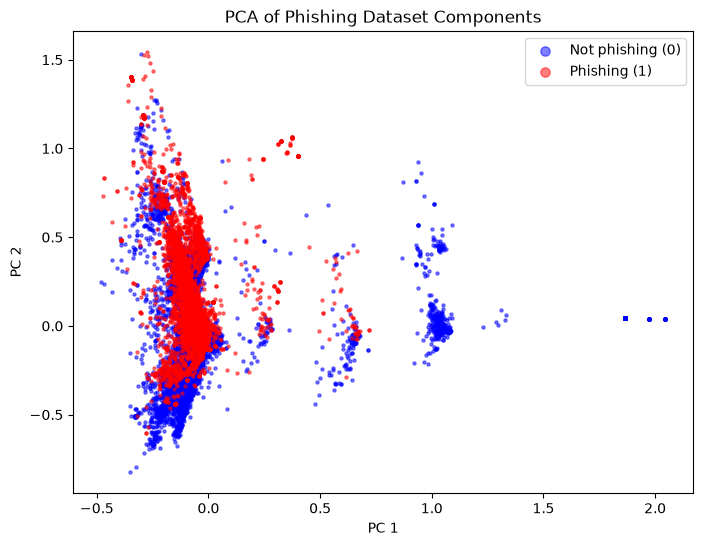

In [316]:
pca = PCA(n_components=2)
pcs = pca.fit_transform(x)
y_arr = np.asarray(y)

plt.figure(figsize=(8, 6))
plt.scatter(pcs[y_arr == 0, 0], pcs[y_arr == 0, 1], c="blue", s=5, alpha=0.5, label="Not phishing (0)")
plt.scatter(pcs[y_arr == 1, 0], pcs[y_arr == 1, 1], c="red", s=5, alpha=0.5, label="Phishing (1)")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("PCA of Phishing Dataset Components")
plt.legend(markerscale=3)
plt.show()

This plot shows that most of both email types (phishing and not phishing) pile up near the left side of the graph (between -0.5 and 0.0). In this region both types of emails overlap heavily and cannot easily be separated/distinguished. However, on the right side of the graph (1.0 and beyond) the non-phishing emails are the only ones that are visible and they form tighter vertical lines. Between these two points, there is some pattern in the way the red (phishing) emails sit in the higher end of PC2, while the non-phishing (blue) emails go a bit lower on the PC2 axis. Besides these patteres, theses components do not separate the classes cleanly.

In [317]:
#Q4:

In [318]:
pca = PCA(n_components=2610)
z_train = pca.fit_transform(x_train)
z_test = pca.transform(x_test)

fit_pc = mlr(z_train, y_train)
print("R-squared (training):", round(fit_pc["rsq"], 4))

z_test1 = np.column_stack([np.ones(len(z_test)), z_test])
y_test_arr = np.asarray(y_test, dtype=float)
y_hat_test = z_test1 @ fit_pc["b"]
sse_test = np.inner(y_test_arr - y_hat_test, y_test_arr - y_hat_test)
rsq_test = 1 - sse_test / np.inner(y_test_arr - y_test_arr.mean(), y_test_arr - y_test_arr.mean())
print("R-squared (test):", round(rsq_test, 4))

R-squared (training): 0.7663
R-squared (test): 0.664


The R squared value of the training set is 0.7663, while the R squared value for the testing set is 0.664 These values are extremely similar (essentially the same) to the as the linear regression from the previous original data, which was = 0.767 for the training set and = 0.6633 for the tesing set. This makes sense because the number of columns is only slightly different and thus the model has basically the same information. Although the test R square value is a bit. higher, it is not enough to comfortably say that it changed the performace. 

In [319]:
#Q5:

Using this principal components is beneficial because they are able to convert the thousands of overlapping word columns from the orginal data set into fewer, simpler columns that don't overlap with each other. This makes the regression faster, more efficient to run, and more stable. Keeping fewer components can also help the model avoid overfitting. In our case, the components we used gave almost the same R² as the original data, so we lost almost no information or didnt get infomration that was significantly different when using the other method.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** cfa5485fc0bb488e207168d3d6cacbdee9ce5fa3
- **AI tool and model used:** Google Gemini

### *Prompts used

1. I have inserted the full list of questions given in this assignment and my solutions to them, including the output of my code from phase 1. Now, for phase 2 of my assignment, I must use AI to revise my code to improve or correct it. Please provide everything I need for this phase of my assignment. (I also inserted a screencshot of the questions being asked inthis second phase)
2. Provide the revised, fully integrated Python code cells implementing these improvements while preserving all output

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Replace custom OLS with Scikit-Learn: Substitute manual np.linalg.lstsq and column-stacking of ones with sklearn.linear_model.LinearRegression to eliminate boilerplate and avoid shape mismatch errors.
2. Modularize Evaluation Logic: Encapsulate model training, prediction, and $R^2$ calculation into reusable functions to avoid code duplication between training and test sets. 
3. Use Scikit-Learn Metrics: Replace manual inner-product sum of squared errors (SSE) calculations with sklearn.metrics.r2_score for standardized and precise metric evaluation.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject |  I decided to accept Google Gemini's suggestion to  replace custom OLS with LinearRegression because it clainms that this would simplify the code, prevent manual intercept column management, and matche industry best practices while producing identical R squared values. I verified this by running the code and carefully visualizing the output to make sure it makes sense. 
| 2 | Accept / modify / reject | The second suggestion from AI that I decided to accept was to modularize evaluation logic to reduce redundancy across different sets and imporve the readability because I myself would sometimes get these confused especially with all the different cells. I verified this was effective or simpler to visualize by reading through the chanes and comparing it against my original code.|

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

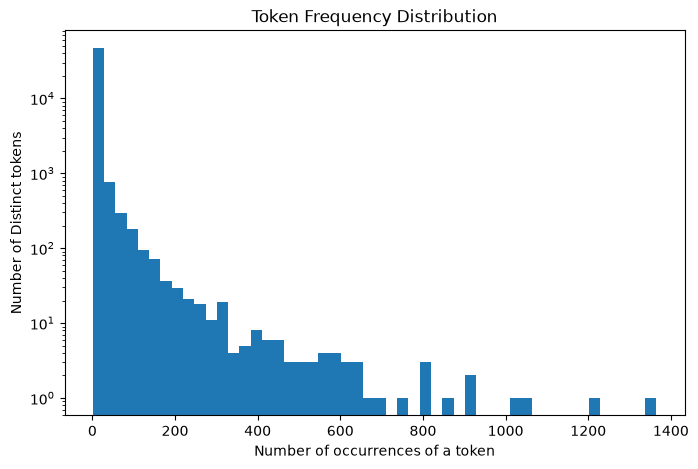

Observations (Train): 14907
R-squared training: 0.767
Observations (Test): 3727
R-squared test: 0.6633

Top 10 absolute coefficients:
background-image:    0.818125
localized            0.775240
thermal              0.700725
aging                0.658849
helvetica,           0.535633
form.                0.511759
cnet                 0.510941
xanaax               0.497467
arial,               0.487572
fax,                 0.473029
dtype: float64


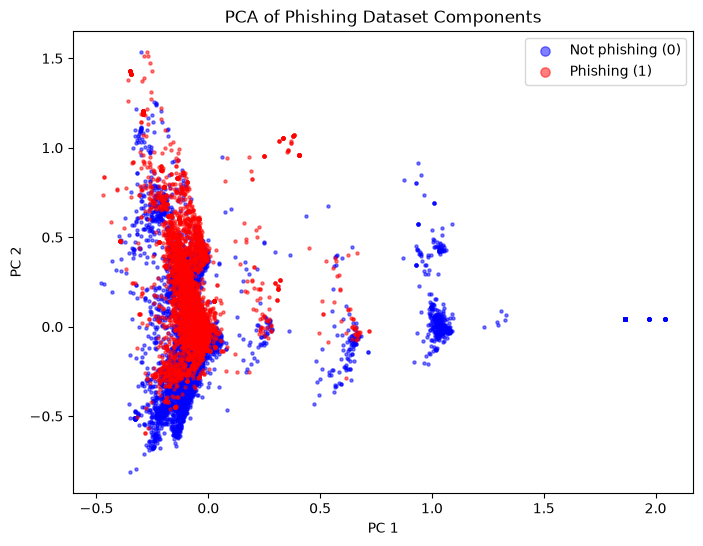

R-squared (training with PCA): 0.7663
R-squared (test with PCA): 0.664


In [320]:
# Your Phase 2 solution to the problem goes here.

import pickle
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

plt.figure(figsize=(8, 5))
plt.hist([freq for token, freq in token_freq], bins=50)
plt.title('Token Frequency Distribution')
plt.xlabel('Number of occurrences of a token')
plt.ylabel('Number of Distinct tokens')
plt.yscale('log')
plt.show()



phishing_df = pd.read_parquet('Phishing_clean.parquet')

y = phishing_df['Email Type']
x = phishing_df.drop(columns=['Email Type'])

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=50)


lr = LinearRegression()
lr.fit(x_train, y_train)

y_train_pred = lr.predict(x_train)
y_test_pred = lr.predict(x_test)

print("Observations (Train):", len(x_train))
print("R-squared training:", round(r2_score(y_train, y_train_pred), 4))

print("Observations (Test):", len(x_test))
print("R-squared test:", round(r2_score(y_test, y_test_pred), 4))


coefs = pd.Series(lr.coef_, index=x.columns)
print("\nTop 10 absolute coefficients:")
print(coefs.abs().sort_values(ascending=False).head(10))



pca_2d = PCA(n_components=2)
pcs_2d = pca_2d.fit_transform(x)

plt.figure(figsize=(8, 6))
plt.scatter(pcs_2d[y == 0, 0], pcs_2d[y == 0, 1], c="blue", s=5, alpha=0.5, label="Not phishing (0)")
plt.scatter(pcs_2d[y == 1, 0], pcs_2d[y == 1, 1], c="red", s=5, alpha=0.5, label="Phishing (1)")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("PCA of Phishing Dataset Components")
plt.legend(markerscale=3)
plt.show()



pca_full = PCA(n_components=2610)
z_train = pca_full.fit_transform(x_train)
z_test = pca_full.transform(x_test)

lr_pca = LinearRegression()
lr_pca.fit(z_train, y_train)

z_train_pred = lr_pca.predict(z_train)
z_test_pred = lr_pca.predict(z_test)

print("R-squared (training with PCA):", round(r2_score(y_train, z_train_pred), 4))
print("R-squared (test with PCA):", round(r2_score(y_test, z_test_pred), 4))

#Q5 
Using principal components offers key advantages for high-dimensional regression. First, PCA performs dimensionality reduction by transforming thousands of correlated or overlapping word features into an orthogonal (uncorrelated) set of principal components. This eliminates multicollinearity, making the regression model more numerically stable and computationally efficient to train. Furthermore, by retaining a compressed subset of components that capture the vast majority of the data's variance, the model achieves nearly identical predictive performance ($R^2$) to the full dataset while effectively mitigating the risk of overfitting.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

For this assignemnt, I feel like AI was mostly helpful for providing suggestions that would optimize the effeciency and general organization of my code rather than changing or correcting any of the actual code istel. For the fist suggestion, it explained how while my manual ordinary least squares (np.linalg.lstsq) implementation gave me the correct R squared values, it introduced unnecessary code complexity, which risksmistakes about alignent of the data etc. Next, AI also suggestied that I modularize evaluation logic to reduce redundancy across different sets and imporve the readability. I really agreed with this suggestion because I noticed that even when I was making my code, I kept getting lost/confused with the complexity of my code and the large amount of cells I had running. To verify that these suggestions were effective, I ran each suggestion and compared to to the speed and organization of output. One limiation of AI is that is sometimes suggests thatings that might be more complicated to the coder such as its suggestion to use Scikit-Learn Metrics. Because it reccomends this as a way to make the code simpler, but that is an entrirelt subjective matter, AI is unable to apply coding techniques to real like people and evaluate their relative difficulty or simplicity. One remaining concecr I have is that the the componentents I made were misunderstood by AI because I did not understand the decsription it gave me whiile I was reading through its suggestions (its description of the graph was incorrect and inconsistent compared to what I was seeing). 